In [3]:

import pandas as pd
import numpy as np
import shap
import sklearn
import xgboost

from pathlib import Path

print("SHAP:", shap.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)

data_dir = Path("../data/processed")
reports_dir = Path("../reports")
models_dir = Path("../models")

reports_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

print("\nProcessed datasets:")
for file in sorted(data_dir.glob("*.csv")):
    print("-", file.name)

print("\nSaved model artifacts:")
for file in sorted(models_dir.iterdir()):
    if file.is_file():
        print("-", file.name)

print("\nSetup complete!")


SHAP: 0.52.0
Scikit-learn: 1.9.1
XGBoost: 3.4.1

Processed datasets:
- maternal_aiovy_candidate_6039.csv
- maternal_paper_candidate_6058.csv

Saved model artifacts:

Setup complete!


In [4]:

# Load the same cleaned dataset used in Notebook 03
df = pd.read_csv(
    data_dir / "maternal_aiovy_candidate_6039.csv"
)

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

print("\nMissing values:")
print(df.isna().sum())

print("\nRisk distribution:")
if "risk_level" in df.columns:
    print(df["risk_level"].value_counts())
else:
    print("Risk column needs identification.")


Dataset shape: (6039, 7)

Columns:
['age', 'systolic_bp', 'diastolic_bp', 'blood_glucose_mmol_l', 'body_temperature_c', 'heart_rate', 'risk_level']

First five records:


,age,systolic_bp,diastolic_bp,blood_glucose_mmol_l,body_temperature_c,heart_rate,risk_level
0,20,161,100,5.8,36.388889,91,high risk
1,45,99,94,5.7,36.500000,99,high risk
2,29,129,87,6.4,37.000000,84,mid risk
3,26,161,101,4.5,37.500000,135,high risk
4,38,106,91,4.3,39.166667,51,high risk



Missing values:
age                     0
systolic_bp             0
diastolic_bp            0
blood_glucose_mmol_l    0
body_temperature_c      0
heart_rate              0
risk_level              0
dtype: int64

Risk distribution:
risk_level
mid risk     2043
low risk     1999
high risk    1997
Name: count, dtype: int64


In [5]:

print("Notebook 03 reports:")

for file in sorted(reports_dir.glob("*")):
    if file.is_file():
        print("-", file.name)

print("\nRepeated nested CV results:")
cv_file = reports_dir / "repeated_nested_cv_folds.csv"

if cv_file.exists():
    cv_results = pd.read_csv(cv_file)
    print("Rows:", len(cv_results))
    print("Models:", cv_results["Model"].unique())
else:
    print("CV report not found.")


Notebook 03 reports:
- cleaning_audit.csv
- nested_cv_pilot_folds.csv
- nested_cv_pilot_summary.csv
- preliminary_best_parameters.json
- preliminary_tuning_results.csv
- repeated_nested_cv_folds.csv
- repeated_nested_cv_summary.csv

Repeated nested CV results:
Rows: 45
Models: <StringArray>
['Logistic Regression', 'Random Forest', 'XGBoost']
Length: 3, dtype: str


In [6]:

from sklearn.model_selection import GroupShuffleSplit
import pandas as pd
import numpy as np

# EXACT feature order from Notebook 03
features = [
    "age",
    "systolic_bp",
    "diastolic_bp",
    "blood_glucose_mmol_l",
    "body_temperature_c",
    "heart_rate"
]

target = "risk_level"

X = df[features]
y = df[target]

# Same grouping method as Notebook 03
group_ids = pd.util.hash_pandas_object(
    df[features],
    index=False
)

# Same original split configuration
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=group_ids)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_group_ids = group_ids.iloc[train_idx]
test_group_ids = group_ids.iloc[test_idx]

# Verify results
overlap = set(train_group_ids) & set(test_group_ids)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Unique training groups:", train_group_ids.nunique())
print("Overlapping groups:", len(overlap))

assert len(X_train) == 4826
assert len(X_test) == 1213
assert len(overlap) == 0

print("\nPASS: Original Notebook 03 split reproduced!")


Training records: 4826
Testing records: 1213
Unique training groups: 4392
Overlapping groups: 0

PASS: Original Notebook 03 split reproduced!


In [7]:

from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedGroupKFold,
    RandomizedSearchCV
)
from sklearn.metrics import make_scorer, recall_score

# Match the label encoding used in Notebook 03
encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train)

print("Label encoding:")
for label, code in zip(
    encoder.classes_,
    encoder.transform(encoder.classes_)
):
    print(f"{label}: {code}")

# Identify the HIGH-risk class
high_risk_code = encoder.transform(["high risk"])[0]

def high_risk_recall(y_true, y_pred):
    return recall_score(
        y_true,
        y_pred,
        labels=[high_risk_code],
        average="macro",
        zero_division=0
    )

# Recreate Notebook 03 Random Forest pipeline
rf_pipeline = Pipeline([
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Same search space as Notebook 03
rf_params = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 8, 12, 20],
    "model__min_samples_leaf": [1, 2, 4],
    "model__class_weight": [None, "balanced"]
}

# Group-aware 5-fold tuning
inner_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Check training-only data alignment
assert len(X_train) == len(y_train_encoded)
assert len(X_train) == len(train_group_ids)
assert len(set(train_group_ids) & set(test_group_ids)) == 0

print("\nRandom Forest pipeline:", list(rf_pipeline.named_steps))
print("Hyperparameter combinations:", 72)
print("Training records:", len(X_train))
print("Locked test records:", len(X_test))
print("\nPASS: Model configuration ready!")


Label encoding:
high risk: 0
low risk: 1
mid risk: 2

Random Forest pipeline: ['model']
Hyperparameter combinations: 72
Training records: 4826
Locked test records: 1213

PASS: Model configuration ready!


In [8]:

import time
from sklearn.model_selection import RandomizedSearchCV

# Optimize for HIGH-risk recall
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_params,
    n_iter=10,
    scoring=make_scorer(high_risk_recall),
    cv=inner_cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True,
    error_score="raise"
)

start_time = time.time()

# Training data ONLY; test set remains untouched
rf_search.fit(
    X_train,
    y_train_encoded,
    groups=train_group_ids
)

elapsed = time.time() - start_time

# Best fitted model
final_rf_model = rf_search.best_estimator_

print("\nTRAINING COMPLETE!")
print(f"Training time: {elapsed / 60:.2f} minutes")

print("\nBest hyperparameters:")
for param, value in rf_search.best_params_.items():
    print(f"  {param}: {value}")

print(
    "\nBest cross-validation HIGH-risk recall:",
    round(rf_search.best_score_, 4)
)

print("\nFinal model:", type(
    final_rf_model.named_steps["model"]
).__name__)

print("Training records used:", len(X_train))
print("Test records used for tuning: 0")


Fitting 5 folds for each of 10 candidates, totalling 50 fits

TRAINING COMPLETE!
Training time: 0.91 minutes

Best hyperparameters:
  model__n_estimators: 100
  model__min_samples_leaf: 1
  model__max_depth: None
  model__class_weight: None

Best cross-validation HIGH-risk recall: 0.8697

Final model: RandomForestClassifier
Training records used: 4826
Test records used for tuning: 0


In [9]:

import joblib
import json
from datetime import datetime, timezone

model_path = models_dir / "aiovy_random_forest.joblib"
config_path = models_dir / "aiovy_random_forest_config.json"

# Save fitted model and label encoder
joblib.dump(
    {
        "model": final_rf_model,
        "label_encoder": encoder,
        "features": features
    },
    model_path
)

# Save training metadata
config = {
    "model": "Random Forest",
    "dataset": "maternal_aiovy_candidate_6039.csv",
    "training_records": len(X_train),
    "locked_test_records": len(X_test),
    "features": features,
    "labels": encoder.classes_.tolist(),
    "high_risk_class_code": int(high_risk_code),
    "best_params": rf_search.best_params_,
    "cv_high_risk_recall": float(rf_search.best_score_),
    "cv_folds": 5,
    "search_iterations": 10,
    "smote_used": False,
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)

# Verify saved files
loaded = joblib.load(model_path)

assert loaded["features"] == features
assert list(loaded["label_encoder"].classes_) == list(
    encoder.classes_
)
assert hasattr(loaded["model"], "predict")

print("MODEL SAVED SUCCESSFULLY!")
print("Model:", model_path)
print("Config:", config_path)
print("File size:", round(
    model_path.stat().st_size / (1024 * 1024), 2
), "MB")

print("\nPASS: Final Random Forest model saved and verified!")


MODEL SAVED SUCCESSFULLY!
Model: ..\models\aiovy_random_forest.joblib
Config: ..\models\aiovy_random_forest_config.json
File size: 7.52 MB

PASS: Final Random Forest model saved and verified!


## Step 03: Held-Out Test Evaluation

Evaluate the finalized Random Forest model on the locked test set.
The model and hyperparameters are fixed before this evaluation.

=== AIOVY HELD-OUT TEST RESULTS ===
Test records: 1213
Accuracy: 0.9291
Macro F1: 0.9290
High-Risk Recall: 0.8653

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

   high risk       0.94      0.87      0.90       401
    low risk       0.96      1.00      0.98       396
    mid risk       0.89      0.93      0.91       416

    accuracy                           0.93      1213
   macro avg       0.93      0.93      0.93      1213
weighted avg       0.93      0.93      0.93      1213



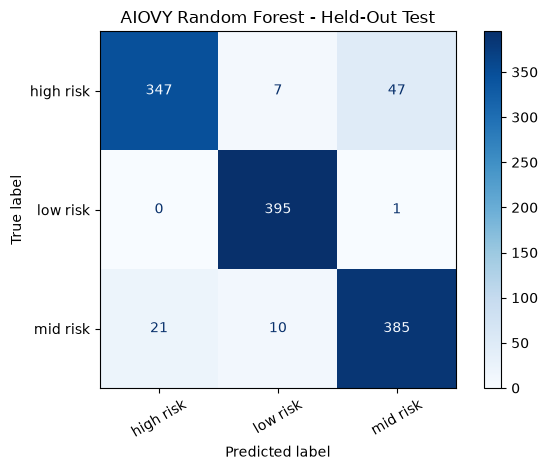


PASS: Held-out evaluation executed.


In [10]:

import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Load the finalized model from Step 02
model_bundle = joblib.load(
    models_dir / "aiovy_random_forest.joblib"
)

model = model_bundle["model"]
saved_encoder = model_bundle["label_encoder"]
saved_features = model_bundle["features"]

# Ensure correct feature order and label encoding
assert saved_features == features
assert list(saved_encoder.classes_) == list(encoder.classes_)
assert len(X_test) == 1213

# Encode the actual test labels
y_test_encoded = saved_encoder.transform(y_test)

# Predict using the locked test set
# No fitting or hyperparameter tuning happens here
y_pred = model.predict(X_test[saved_features])

# Calculate metrics
test_accuracy = accuracy_score(y_test_encoded, y_pred)
test_macro_f1 = f1_score(
    y_test_encoded, y_pred, average="macro"
)

test_high_recall = recall_score(
    y_test_encoded,
    y_pred,
    labels=[high_risk_code],
    average="macro",
    zero_division=0
)

print("=== AIOVY HELD-OUT TEST RESULTS ===")
print("Test records:", len(X_test))
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Macro F1: {test_macro_f1:.4f}")
print(f"High-Risk Recall: {test_high_recall:.4f}")

print("\n=== CLASSIFICATION REPORT ===")
print(
    classification_report(
        y_test_encoded,
        y_pred,
        labels=np.arange(len(saved_encoder.classes_)),
        target_names=saved_encoder.classes_,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test_encoded,
    y_pred,
    labels=np.arange(len(saved_encoder.classes_))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=saved_encoder.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("AIOVY Random Forest - Held-Out Test")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("\nPASS: Held-out evaluation executed.")


In [11]:

# Identify actual high-risk patients in the test dataset
actual_high = (y_test_encoded == high_risk_code)

# Count how many were correctly identified
correct_high = np.sum(
    actual_high & (y_pred == high_risk_code)
)

# Count how many high-risk records were missed
missed_high = np.sum(
    actual_high & (y_pred != high_risk_code)
)

total_high = np.sum(actual_high)

print("=== HIGH-RISK DETECTION ANALYSIS ===")
print("Actual high-risk records:", total_high)
print("Correctly detected high-risk:", correct_high)
print("Missed high-risk records:", missed_high)

print(
    "High-risk recall:",
    f"{correct_high / total_high * 100:.2f}%"
)

# Show which risk classes the missed records were assigned to
missed_predictions = saved_encoder.inverse_transform(
    y_pred[actual_high & (y_pred != high_risk_code)]
)

print("\nMissed high-risk records predicted as:")
print(pd.Series(missed_predictions).value_counts())

# Verify consistency with the metric above
assert np.isclose(
    correct_high / total_high,
    test_high_recall
)

print("\nPASS: High-risk error analysis verified.")


=== HIGH-RISK DETECTION ANALYSIS ===
Actual high-risk records: 401
Correctly detected high-risk: 347
Missed high-risk records: 54
High-risk recall: 86.53%

Missed high-risk records predicted as:
mid risk    47
low risk     7
Name: count, dtype: int64

PASS: High-risk error analysis verified.


## Step 04: SHAP Explainability

This section uses SHAP to explain the finalized Random Forest
model's predictions. SHAP values represent contributions to
model outputs, not causal or clinical relationships.

In [12]:

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# Retrieve the fitted Random Forest classifier
rf_classifier = model.named_steps["model"]

# Use a reproducible subset for initial SHAP analysis
# This does not modify the fitted model.
X_shap = X_test[saved_features].sample(
    n=min(200, len(X_test)),
    random_state=42
)

print("SHAP version:", shap.__version__)
print("Model:", type(rf_classifier).__name__)
print("SHAP sample size:", len(X_shap))
print("Features:", X_shap.columns.tolist())

# TreeExplainer supports Random Forest
explainer = shap.TreeExplainer(rf_classifier)

start = time.time()
shap_values = explainer(X_shap)
elapsed = time.time() - start

print("\nSHAP computation finished!")
print("SHAP values shape:", shap_values.values.shape)
print("Base values shape:", np.asarray(
    shap_values.base_values
).shape)
print(f"Time: {elapsed:.2f} seconds")

# For multiclass Random Forest:
# expected: (samples, features, classes)
assert shap_values.values.shape == (
    len(X_shap),
    len(saved_features),
    len(saved_encoder.classes_)
)

print("\nClass mapping:")
for i, label in enumerate(saved_encoder.classes_):
    print(f"{i}: {label}")

print("\nPASS: SHAP initialized successfully!")


SHAP version: 0.52.0
Model: RandomForestClassifier
SHAP sample size: 200
Features: ['age', 'systolic_bp', 'diastolic_bp', 'blood_glucose_mmol_l', 'body_temperature_c', 'heart_rate']

SHAP computation finished!
SHAP values shape: (200, 6, 3)
Base values shape: (200, 3)
Time: 1.30 seconds

Class mapping:
0: high risk
1: low risk
2: mid risk

PASS: SHAP initialized successfully!


GLOBAL SHAP FEATURE IMPORTANCE


,Feature,Mean Absolute SHAP
1,systolic_bp,0.130889
5,heart_rate,0.088807
4,body_temperature_c,0.079097
2,diastolic_bp,0.067472
0,age,0.057080
3,blood_glucose_mmol_l,0.053433


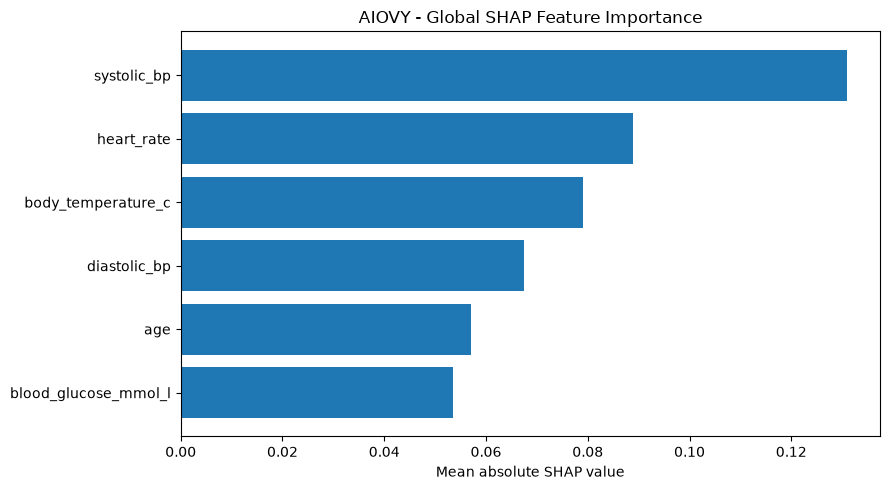


PASS: Global feature importance generated!


In [13]:

# Mean absolute SHAP values across all sampled records
# and all three output classes
mean_abs_shap = np.abs(
    shap_values.values
).mean(axis=(0, 2))

importance_df = pd.DataFrame({
    "Feature": saved_features,
    "Mean Absolute SHAP": mean_abs_shap
}).sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

print("GLOBAL SHAP FEATURE IMPORTANCE")
display(importance_df)

plt.figure(figsize=(9, 5))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Mean Absolute SHAP"][::-1]
)

plt.xlabel("Mean absolute SHAP value")
plt.title("AIOVY - Global SHAP Feature Importance")
plt.tight_layout()
plt.show()

print("\nPASS: Global feature importance generated!")


High-risk SHAP shape: (200, 6)


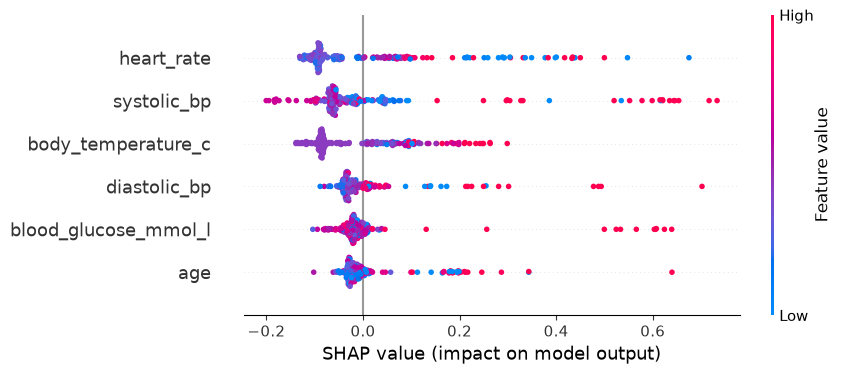


PASS: High-risk beeswarm generated!


In [14]:

# High-risk class index = 0
high_idx = int(high_risk_code)

# Select SHAP explanations for the HIGH-risk class
high_risk_shap = shap_values[:, :, high_idx]

print("High-risk SHAP shape:", high_risk_shap.values.shape)

# Beeswarm: feature values and their influence
shap.plots.beeswarm(
    high_risk_shap,
    max_display=6,
    show=True
)

print("\nPASS: High-risk beeswarm generated!")


=== EXAMPLE RECORD ===


,age,systolic_bp,diastolic_bp,blood_glucose_mmol_l,body_temperature_c,heart_rate
199,39,113,97,4.2,35.833333,53


Predicted risk: high risk

Predicted probabilities:
high risk: 100.00%
low risk: 0.00%
mid risk: 0.00%


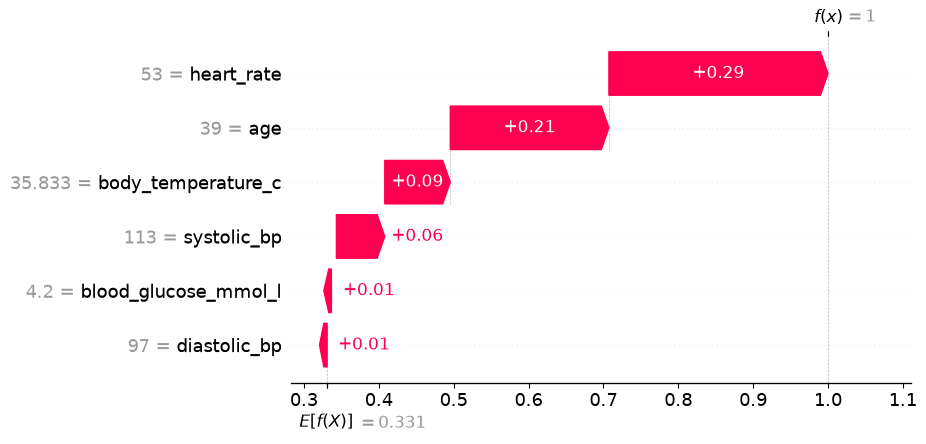


SHAP reconstruction: 0.9999999999999822
Model high-risk probability: 1.0

PASS: Individual SHAP explanation verified!


In [15]:

# Predict on the same 200 sampled records
sample_predictions = model.predict(X_shap)

# Find the first predicted high-risk record
high_positions = np.where(
    sample_predictions == high_risk_code
)[0]

assert len(high_positions) > 0, (
    "No predicted high-risk records found in SHAP sample."
)

patient_position = int(high_positions[0])

patient_data = X_shap.iloc[[patient_position]]
patient_prediction = model.predict(patient_data)[0]
patient_probabilities = model.predict_proba(patient_data)[0]

print("=== EXAMPLE RECORD ===")
display(patient_data)

print(
    "Predicted risk:",
    saved_encoder.inverse_transform(
        [patient_prediction]
    )[0]
)

print("\nPredicted probabilities:")
for label, probability in zip(
    saved_encoder.classes_,
    patient_probabilities
):
    print(f"{label}: {probability:.2%}")

# Waterfall explanation for high-risk probability
shap.plots.waterfall(
    high_risk_shap[patient_position],
    max_display=6,
    show=True
)

# Verify SHAP additivity against model output
base_value = float(
    high_risk_shap.base_values[patient_position]
)

shap_contribution = float(
    high_risk_shap.values[patient_position].sum()
)

reconstructed_probability = (
    base_value + shap_contribution
)

actual_probability = float(
    patient_probabilities[high_idx]
)

print("\nSHAP reconstruction:", reconstructed_probability)
print("Model high-risk probability:", actual_probability)

assert np.isclose(
    reconstructed_probability,
    actual_probability,
    atol=1e-5
)

print("\nPASS: Individual SHAP explanation verified!")


In [16]:

print("SHAP reconstructed probability:",
      round(reconstructed_probability, 6))

print("Model high-risk probability:",
      round(actual_probability, 6))

print("Difference:",
      abs(reconstructed_probability - actual_probability))

assert np.isclose(
    reconstructed_probability,
    actual_probability,
    atol=1e-5
)

print("\nPASS: SHAP explanation verified!")


SHAP reconstructed probability: 1.0
Model high-risk probability: 1.0
Difference: 1.7763568394002505e-14

PASS: SHAP explanation verified!


## Step 05: SHAP Stability Analysis

Evaluate the stability of Random Forest global SHAP feature
importance across five group-aware training folds.

A fixed reference sample from the training partition is used
for all fold-specific models. The locked test set is excluded
from this stability analysis.

In [17]:

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from scipy.stats import spearmanr
import shap
import numpy as np
import pandas as pd
import time

# Fixed reference sample from TRAINING data only
X_reference = X_train.sample(
    n=min(200, len(X_train)),
    random_state=42
)

# Use the selected final RF configuration
stability_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_importances = []
start_time = time.time()

for fold, (train_fold_idx, val_fold_idx) in enumerate(
    stability_cv.split(
        X_train,
        y_train_encoded,
        groups=train_group_ids
    ),
    start=1
):
    # Ensure training and validation groups are disjoint
    fold_train_groups = set(
        train_group_ids.iloc[train_fold_idx]
    )
    fold_val_groups = set(
        train_group_ids.iloc[val_fold_idx]
    )

    assert not fold_train_groups.intersection(
        fold_val_groups
    )

    # Fit a new model on this fold's training subset
    fold_model = clone(final_rf_model)

    fold_model.fit(
        X_train.iloc[train_fold_idx],
        y_train_encoded[train_fold_idx]
    )

    # SHAP on the SAME fixed reference records
    fold_explainer = shap.TreeExplainer(
        fold_model.named_steps["model"]
    )

    fold_shap = fold_explainer(X_reference)

    # Global importance for HIGH-risk output only
    high_values = fold_shap.values[:, :, high_risk_code]

    mean_importance = np.abs(
        high_values
    ).mean(axis=0)

    fold_importances.append(mean_importance)

    print(f"Fold {fold}/5 completed.")

elapsed = time.time() - start_time

# Convert to a table
stability_df = pd.DataFrame(
    fold_importances,
    columns=features,
    index=[f"Fold {i}" for i in range(1, 6)]
)

print(f"\nTotal time: {elapsed:.2f} seconds")
print("\nHigh-risk SHAP importance by fold:")
display(stability_df.round(4))

assert stability_df.shape == (5, 6)
assert np.isfinite(stability_df.to_numpy()).all()

print("\nPASS: Five-fold SHAP importance computed!")


Fold 1/5 completed.
Fold 2/5 completed.
Fold 3/5 completed.
Fold 4/5 completed.
Fold 5/5 completed.

Total time: 12.88 seconds

High-risk SHAP importance by fold:


,age,systolic_bp,diastolic_bp,blood_glucose_mmol_l,body_temperature_c,heart_rate
Fold 1,0.0345,0.1065,0.0429,0.0450,0.0975,0.1143
Fold 2,0.0386,0.1050,0.0377,0.0456,0.1109,0.1046
Fold 3,0.0392,0.1028,0.0402,0.0441,0.0981,0.1180
Fold 4,0.0359,0.1044,0.0423,0.0410,0.1001,0.1156
Fold 5,0.0362,0.1084,0.0385,0.0458,0.0951,0.1178



PASS: Five-fold SHAP importance computed!


In [18]:

from itertools import combinations
from scipy.stats import spearmanr

correlations = []

for fold_a, fold_b in combinations(
    stability_df.index, 2
):
    rho, p_value = spearmanr(
        stability_df.loc[fold_a],
        stability_df.loc[fold_b]
    )

    correlations.append({
        "Fold A": fold_a,
        "Fold B": fold_b,
        "Spearman rho": rho
    })

correlation_df = pd.DataFrame(correlations)

print("PAIRWISE SHAP RANK CORRELATIONS")
display(correlation_df.round(4))

mean_rho = correlation_df["Spearman rho"].mean()
min_rho = correlation_df["Spearman rho"].min()
max_rho = correlation_df["Spearman rho"].max()

print(f"\nMean Spearman rho: {mean_rho:.4f}")
print(f"Minimum rho: {min_rho:.4f}")
print(f"Maximum rho: {max_rho:.4f}")

assert len(correlation_df) == 10
assert correlation_df["Spearman rho"].notna().all()

print("\nPASS: SHAP ranking stability calculated!")


PAIRWISE SHAP RANK CORRELATIONS


,Fold A,Fold B,Spearman rho
0,Fold 1,Fold 2,0.7143
1,Fold 1,Fold 3,1.0000
2,Fold 1,Fold 4,0.9429
3,Fold 1,Fold 5,1.0000
4,Fold 2,Fold 3,0.7143
5,Fold 2,Fold 4,0.6000
6,Fold 2,Fold 5,0.7143
7,Fold 3,Fold 4,0.9429
8,Fold 3,Fold 5,1.0000
9,Fold 4,Fold 5,0.9429



Mean Spearman rho: 0.8571
Minimum rho: 0.6000
Maximum rho: 1.0000

PASS: SHAP ranking stability calculated!


In [19]:

# Rank 1 = most influential feature
rank_df = stability_df.rank(
    axis=1,
    ascending=False,
    method="average"
)

stability_summary = pd.DataFrame({
    "Feature": features,
    "Mean SHAP": stability_df.mean(axis=0).values,
    "SHAP Std": stability_df.std(axis=0).values,
    "Mean Rank": rank_df.mean(axis=0).values,
    "Rank Std": rank_df.std(axis=0).values
}).sort_values("Mean Rank")

print("SHAP STABILITY SUMMARY")
display(stability_summary.round(4))

print("\nMost consistently influential features:")
print(stability_summary["Feature"].head(3).tolist())

print("\nPASS: SHAP stability summary generated!")


SHAP STABILITY SUMMARY


,Feature,Mean SHAP,SHAP Std,Mean Rank,Rank Std
5,heart_rate,0.1141,0.0055,1.4,0.8944
1,systolic_bp,0.1054,0.0021,2.0,0.0000
4,body_temperature_c,0.1003,0.0062,2.6,0.8944
3,blood_glucose_mmol_l,0.0443,0.0019,4.2,0.4472
2,diastolic_bp,0.0403,0.0023,5.0,0.7071
0,age,0.0369,0.0020,5.8,0.4472



Most consistently influential features:
['heart_rate', 'systolic_bp', 'body_temperature_c']

PASS: SHAP stability summary generated!


## Step 06: Export Results and Documentation

Export held-out test metrics, prediction records, SHAP
importance, stability analysis, and reproducibility metadata.

All exported results are derived from completed experiments.

In [20]:

import json
import pandas as pd
import numpy as np
from pathlib import Path
from datetime import datetime, timezone

# Create dedicated Notebook 04 output folder
output_dir = reports_dir / "notebook_04"
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Held-out test metrics
test_metrics_df = pd.DataFrame([{
    "Model": "Random Forest",
    "Test Records": len(X_test),
    "Accuracy": test_accuracy,
    "Macro F1": test_macro_f1,
    "High-Risk Recall": test_high_recall,
    "Actual High Risk": int(total_high),
    "Correctly Detected High Risk": int(correct_high),
    "Missed High Risk": int(missed_high)
}])

test_metrics_df.to_csv(
    output_dir / "heldout_test_metrics.csv",
    index=False
)

# 2. Confusion matrix
confusion_df = pd.DataFrame(
    cm,
    index=saved_encoder.classes_,
    columns=saved_encoder.classes_
)
confusion_df.index.name = "Actual Risk"
confusion_df.to_csv(
    output_dir / "confusion_matrix.csv"
)

# 3. Test predictions and probabilities
test_probabilities = model.predict_proba(
    X_test[saved_features]
)

predictions_df = X_test[
    saved_features
].copy()

predictions_df["actual_risk"] = (
    saved_encoder.inverse_transform(y_test_encoded)
)
predictions_df["predicted_risk"] = (
    saved_encoder.inverse_transform(y_pred)
)

for class_idx, class_name in enumerate(
    saved_encoder.classes_
):
    safe_name = class_name.replace(" ", "_")
    predictions_df[f"prob_{safe_name}"] = (
        test_probabilities[:, class_idx]
    )

predictions_df.to_csv(
    output_dir / "heldout_test_predictions.csv",
    index_label="source_row_index"
)

print("PASS: Held-out test results exported!")
print("Folder:", output_dir.resolve())


PASS: Held-out test results exported!
Folder: C:\Users\Kenjo Condez\Downloads\aiovy_flutter_prototype (1)\aiovy\ml_model\reports\notebook_04


In [21]:

import matplotlib.pyplot as plt
import shap

# 1. SHAP global importance table
importance_df.to_csv(
    output_dir / "shap_global_importance.csv",
    index=False
)

# 2. SHAP stability tables
stability_df.to_csv(
    output_dir / "shap_fold_importance.csv",
    index_label="Fold"
)

correlation_df.to_csv(
    output_dir / "shap_rank_correlations.csv",
    index=False
)

stability_summary.to_csv(
    output_dir / "shap_stability_summary.csv",
    index=False
)

# 3. Global importance plot
fig, ax = plt.subplots(figsize=(9, 5))

ordered = importance_df.sort_values(
    "Mean Absolute SHAP"
)

ax.barh(
    ordered["Feature"],
    ordered["Mean Absolute SHAP"]
)
ax.set_xlabel("Mean absolute SHAP value")
ax.set_title("AIOVY - Global SHAP Feature Importance")
fig.tight_layout()

fig.savefig(
    output_dir / "shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close(fig)

# 4. High-risk beeswarm
shap.plots.beeswarm(
    high_risk_shap,
    max_display=6,
    show=False
)
plt.savefig(
    output_dir / "shap_high_risk_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close("all")

# 5. Individual high-risk waterfall
shap.plots.waterfall(
    high_risk_shap[patient_position],
    max_display=6,
    show=False
)
plt.savefig(
    output_dir / "shap_individual_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close("all")

# 6. Confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=saved_encoder.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("AIOVY Random Forest - Held-Out Test")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    output_dir / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close("all")

print("PASS: SHAP tables and figures exported!")


PASS: SHAP tables and figures exported!


In [22]:

import sklearn
import xgboost

metadata = {
    "project": "AIOVY",
    "notebook": "04_shap_explainability.ipynb",
    "experiment": "Final RF evaluation and SHAP analysis",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "dataset": "maternal_aiovy_candidate_6039.csv",
    "dataset_records": len(df),
    "training_records": len(X_train),
    "test_records": len(X_test),
    "features": saved_features,
    "classes": saved_encoder.classes_.tolist(),
    "model": "Random Forest",
    "selected_hyperparameters": rf_search.best_params_,
    "smote_used": False,
    "split": {
        "method": "GroupShuffleSplit",
        "test_size": 0.20,
        "random_state": 42,
        "group_overlap": len(overlap)
    },
    "test_metrics": {
        "accuracy": float(test_accuracy),
        "macro_f1": float(test_macro_f1),
        "high_risk_recall": float(test_high_recall)
    },
    "shap": {
        "sample_size": len(X_shap),
        "stability_folds": 5,
        "mean_pairwise_spearman": float(mean_rho),
        "min_pairwise_spearman": float(min_rho),
        "max_pairwise_spearman": float(max_rho)
    },
    "versions": {
        "shap": shap.__version__,
        "scikit_learn": sklearn.__version__,
        "xgboost": xgboost.__version__
    },
    "limitations": [
        "Clinical validity not established",
        "Glucose source units require verification",
        "Risk-label provenance requires verification",
        "SMOTE methodology requires reconciliation",
        "SHAP stability uses a fixed training reference sample"
    ]
}

metadata_path = output_dir / "experiment_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

required_files = [
    "heldout_test_metrics.csv",
    "confusion_matrix.csv",
    "heldout_test_predictions.csv",
    "shap_global_importance.csv",
    "shap_fold_importance.csv",
    "shap_rank_correlations.csv",
    "shap_stability_summary.csv",
    "shap_global_importance.png",
    "shap_high_risk_beeswarm.png",
    "shap_individual_waterfall.png",
    "confusion_matrix.png",
    "experiment_metadata.json"
]

print("=== NOTEBOOK 04 EXPORT VERIFICATION ===")

for filename in required_files:
    path = output_dir / filename
    assert path.exists(), f"Missing file: {filename}"
    assert path.stat().st_size > 0, (
        f"Empty file: {filename}"
    )
    print("PASS:", filename)

# Final integrity checks
assert int(confusion_df.to_numpy().sum()) == len(X_test)
assert len(predictions_df) == len(X_test)
assert len(stability_df) == 5
assert len(correlation_df) == 10

print("\nALL EXPORT CHECKS PASSED!")
print("Files verified:", len(required_files))
print("Output folder:", output_dir.resolve())


=== NOTEBOOK 04 EXPORT VERIFICATION ===
PASS: heldout_test_metrics.csv
PASS: confusion_matrix.csv
PASS: heldout_test_predictions.csv
PASS: shap_global_importance.csv
PASS: shap_fold_importance.csv
PASS: shap_rank_correlations.csv
PASS: shap_stability_summary.csv
PASS: shap_global_importance.png
PASS: shap_high_risk_beeswarm.png
PASS: shap_individual_waterfall.png
PASS: confusion_matrix.png
PASS: experiment_metadata.json

ALL EXPORT CHECKS PASSED!
Files verified: 12
Output folder: C:\Users\Kenjo Condez\Downloads\aiovy_flutter_prototype (1)\aiovy\ml_model\reports\notebook_04
